# LeetCode #143: Reorder List

https://leetcode.com/problems/reorder-list/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Store in Array | O(n) | O(n) |
| Find Middle + Reverse + Merge ★ | O(n) | O(1) |

## Understanding the Methods
### Brute Force (Array)
Store all nodes in an array. Use two pointers (left and right) to reconstruct the list by alternating from both ends. O(n) time and space.

### Optimal: Find Middle + Reverse + Merge ★
Three-step approach:
1. Find the middle of the list (slow/fast pointers)
2. Reverse the second half
3. Merge the two halves by interleaving nodes
O(n) time, O(1) space.

## Solutions
### C#

In [ ]:
// Find Middle + Reverse + Merge O(n) time, O(1) space
public class Solution {
    public void ReorderList(ListNode head) {
        if (head?.next == null) return;
        // Find middle
        var slow = head; var fast = head;
        while (fast.next != null && fast.next.next != null) {
            slow = slow.next; fast = fast.next.next;
        }
        // Reverse second half
        ListNode prev = null; var cur = slow.next; slow.next = null;
        while (cur != null) { var next = cur.next; cur.next = prev; prev = cur; cur = next; }
        // Merge
        var first = head; var second = prev;
        while (second != null) {
            var tmp1 = first.next; var tmp2 = second.next;
            first.next = second; second.next = tmp1;
            first = tmp1; second = tmp2;
        }
    }
}

### Python

In [ ]:
# Find Middle + Reverse + Merge O(n) time, O(1) space
class Solution:
    def reorderList(self, head: 'Optional[ListNode]') -> None:
        if not head or not head.next:
            return
        # Find middle
        slow, fast = head, head
        while fast.next and fast.next.next:
            slow = slow.next
            fast = fast.next.next
        # Reverse second half
        prev, cur = None, slow.next
        slow.next = None
        while cur:
            nxt = cur.next
            cur.next = prev
            prev, cur = cur, nxt
        # Merge
        first, second = head, prev
        while second:
            tmp1, tmp2 = first.next, second.next
            first.next = second
            second.next = tmp1
            first, second = tmp1, tmp2

### Go

In [ ]:
// Find Middle + Reverse + Merge O(n) time, O(1) space
func reorderList(head *ListNode) {
    if head == nil || head.Next == nil { return }
    // Find middle
    slow, fast := head, head
    for fast.Next != nil && fast.Next.Next != nil {
        slow = slow.Next; fast = fast.Next.Next
    }
    // Reverse second half
    var prev *ListNode
    cur := slow.Next
    slow.Next = nil
    for cur != nil { next := cur.Next; cur.Next = prev; prev = cur; cur = next }
    // Merge
    first, second := head, prev
    for second != nil {
        tmp1, tmp2 := first.Next, second.Next
        first.Next = second; second.Next = tmp1
        first, second = tmp1, tmp2
    }
}

### Rust

In [ ]:
// Reorder list using Vec to store nodes (O(n) space)
// Note: In-place O(1) space approach is complex with Rust's ownership model
impl Solution {
    pub fn reorder_list(head: &mut Option<Box<ListNode>>) {
        let mut nodes = Vec::new();
        let mut cur = head.take();
        while let Some(mut node) = cur {
            cur = node.next.take();
            nodes.push(node);
        }
        let (mut left, mut right) = (0usize, nodes.len().saturating_sub(1));
        let mut dummy = Box::new(ListNode::new(0));
        let mut tail = &mut dummy.next;
        while left < right {
            // attach left
            *tail = Some(nodes.remove(left));
            tail = &mut tail.as_mut().unwrap().next;
            // attach right (indices shifted)
            *tail = Some(nodes.remove(right - left - 1));
            tail = &mut tail.as_mut().unwrap().next;
            left += 1; right -= 1;
        }
        if left == right { *tail = Some(nodes.remove(0)); }
        *head = dummy.next.take();
    }
}

## Examples

### 1. Common Case — Even Length
**Input:** `head=[1,2,3,4]`

Split into $[1,2]$ and $[3,4]$, reverse the second half to $[4,3]$, then merge alternately: $1\to4\to2\to3$.

### 2. Slightly Complex — Odd Length
**Input:** `head=[1,2,3,4,5]`

The middle node $3$ stays in the first half $[1,2,3]$; reverse $[4,5]$ to $[5,4]$ and interleave to get $1\to5\to2\to4\to3$.

### 3. Edge Case: Time Factor — Single Node
**Input:** `head=[1]`

One node is already its own reordering; the middle is the node itself and nothing is merged. Output $[1]$.

### 4. Edge Case: Space Factor — Two Nodes
**Input:** `head=[1,2]`

Halves $[1]$ and $[2]$; reversing a single node changes nothing and the merge restores $[1,2]$. $O(1)$ space.

### 5. Almost-Impossible but Plausible — Longer Even Length
**Input:** `head=[1,2,3,4,5,6]`

Split into $[1,2,3]$ and $[4,5,6]$, reverse to $[6,5,4]$, interleave to $1\to6\to2\to5\to3\to4$.


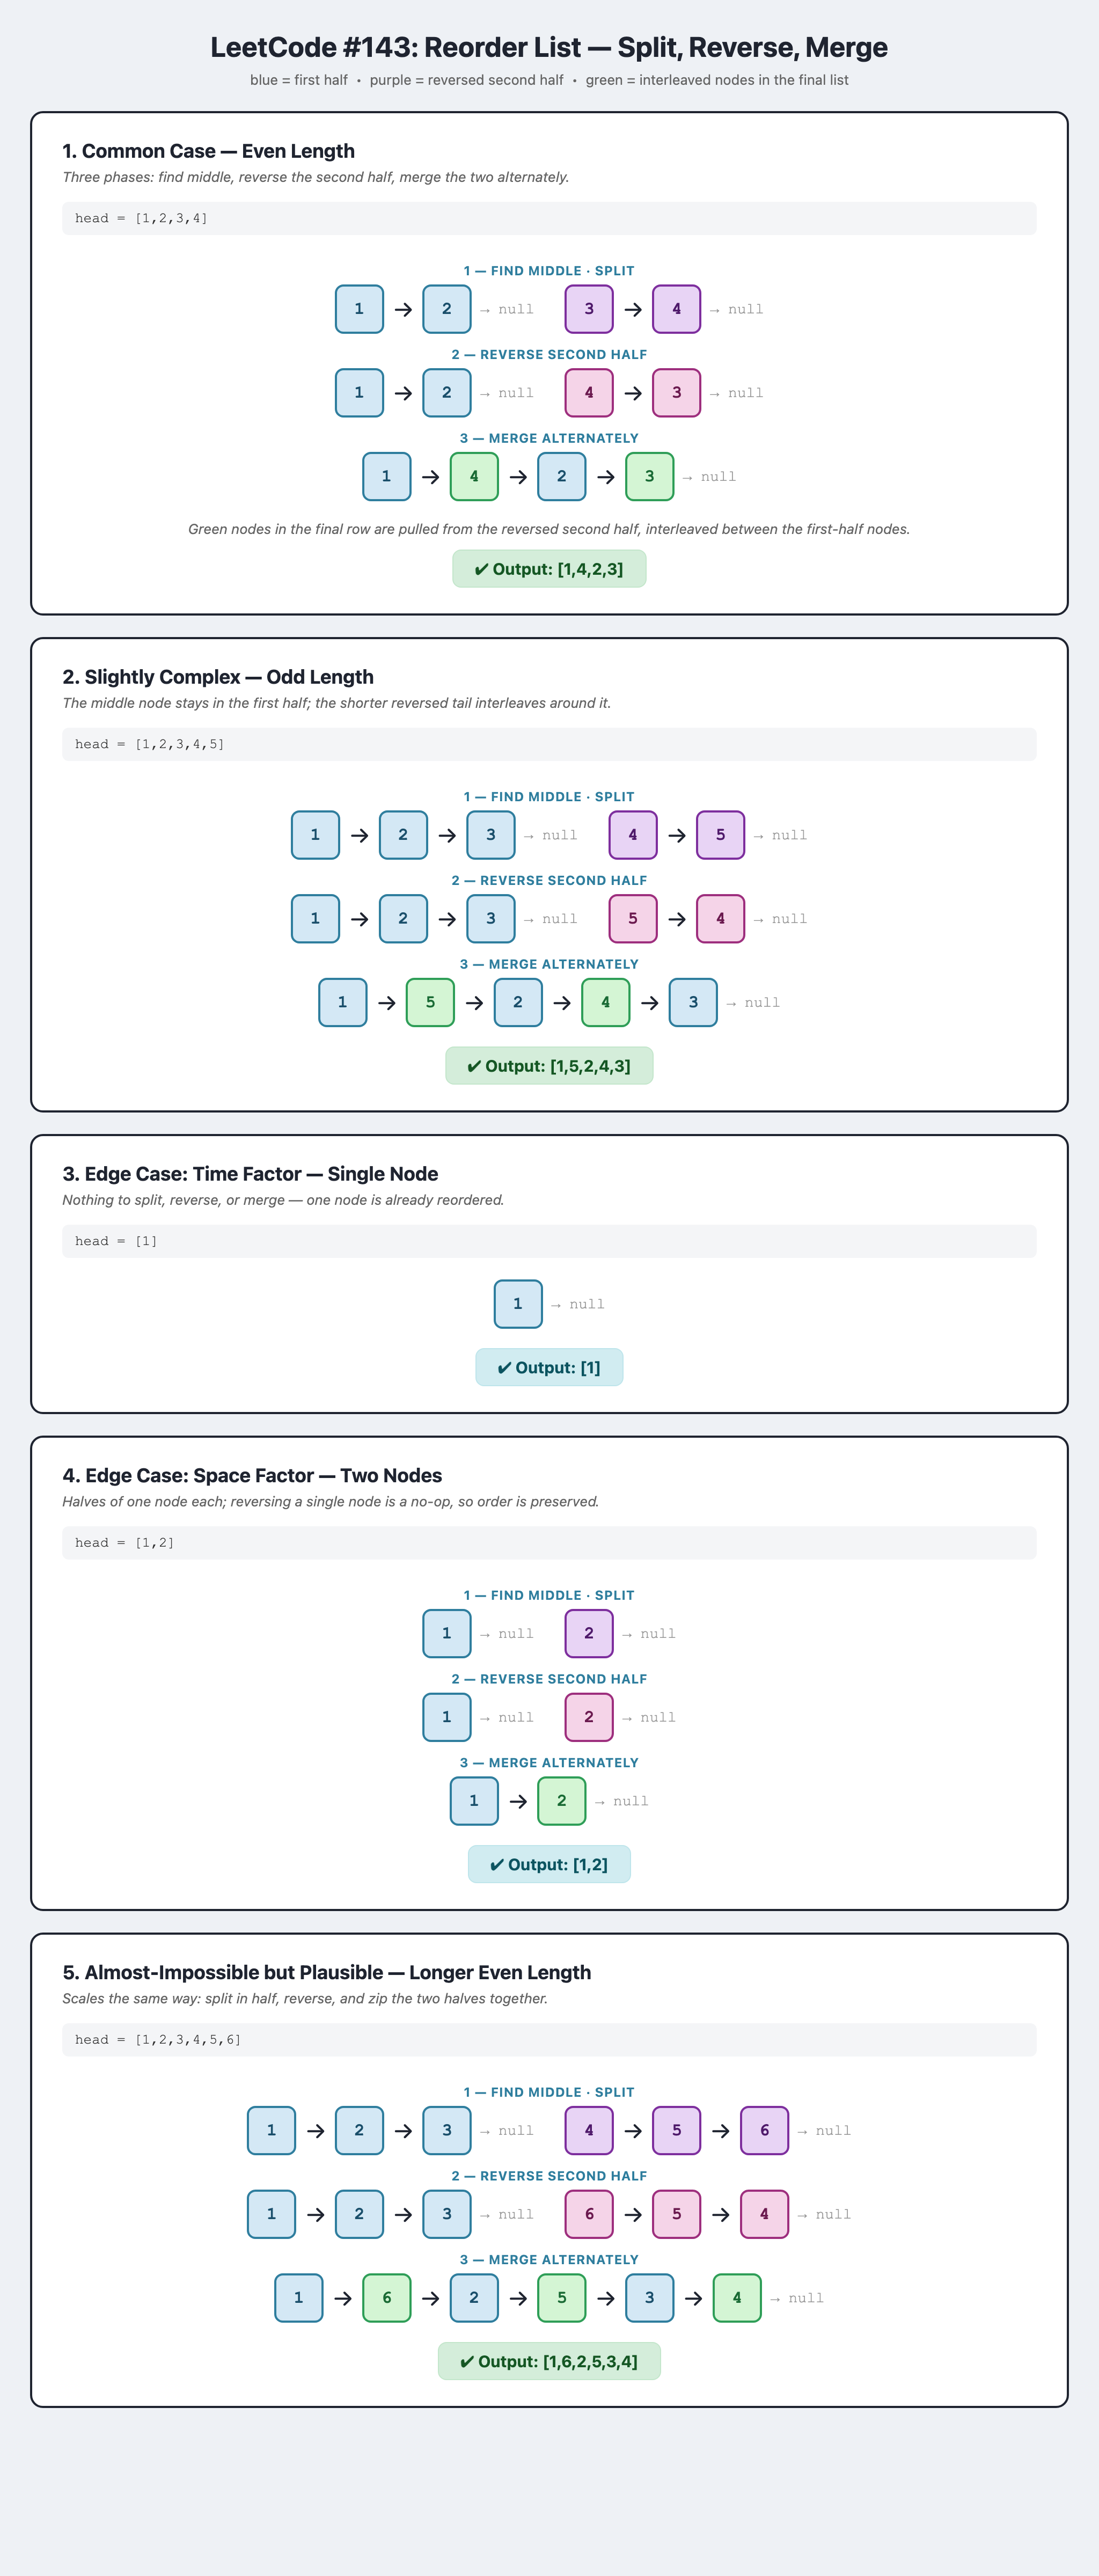